In [1]:
import os

api_key = os.getenv("AICREDITS_API_KEY")
base_url = os.getenv("AICREDITS_BASE_URL")

In [2]:
from langchain_openai import ChatOpenAI

llm_small = ChatOpenAI(model="google/gemini-2.5-flash-lite", 
                       api_key=api_key,
                      base_url=base_url,temperature=1.0)

In [3]:
from datasets import load_dataset
ds = load_dataset("cais/mmlu", "high_school_geography")
ds_dict = ds["test"].take(2).to_dict()
print(ds_dict["question"][0])

The main factor preventing subsistence economies from advancing economically is the lack of


In [4]:
print(ds_dict["choices"][0])

['a currency.', 'a well-connected transportation infrastructure.', 'government activity.', 'a banking service.']


let us create a ReACT agent

In [5]:
from langchain_community.agent_toolkits.load_tools import load_tools
from langgraph.prebuilt import create_react_agent


research_tools = load_tools(
  tool_names=["ddg-search", "arxiv"], "wikipedia"],
  llm=llm_small
)

system_prompt = (
    "You're a hard-working, curious and creative student. "
    "You're working on exam quesion. Think step by step."
    "Always provide an argumentation for your answer. "
    "Do not assume anything, use available tools to search "
    "for evidence and supporting statements."
)

C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_18656\1208690155.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.agent_toolkits.load_tools import load_tools


In [7]:
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate
from langgraph.graph import MessagesState
from langgraph.prebuilt.chat_agent_executor import AgentState
from typing import Optional
#from langchain.agents import create_react_agent

raw_prompt_template = (
    "Answer the following multiple-choice-question. "
    "\nQUESTION:\n{question}\n\nANSWER OPTIONS:\n{options}\n"
)

prompt = ChatPromptTemplate.from_messages(
    [("system", system_prompt),
     ("user", raw_prompt_template),
     ("placeholder", "{messages}")]
)

class ResearchState(AgentState):
    question:str
    options:str
    answer: Optional[str] = None

research_agent = create_react_agent(
    model=llm_small, tools=research_tools, state_schema=ResearchState, prompt=prompt
)

C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_18656\1039862455.py:23: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


Now we define another agent that reflects on the anwer and provides critique:

In [8]:
from pydantic import BaseModel, Field
from typing import Optional

reflection_prompt = (
    "You are a university professor and you're supervising a student who is "
    "working on a multiple-choice exam question."
    "\nQUESTION: {question}.\nANSWER OPTIONS:\n{options}\n."
    "STUDENT'S ANSWER:\n{answer}\n"
    "Reflect on the student's reasoning and decide whether the answer is right "
    "or wrong. Respond with exactly one of the two fields, never both:\n"
    "- If the answer is correct and sufficiently supported by the reasoning, "
    "fill in 'answer' with the final answer and leave 'critique' empty.\n"
    "- If the answer might be incorrect or the reasoning has flaws, fill in "
    "'critique' with actionable feedback and leave 'answer' empty.\n"
    "Do not assume anything; evaluate only the reasoning the student provided "
    "and whether there is enough evidence for their answer."
)

class Response(BaseModel):
    """A final response to the user"""
    answer: Optional[str]= Field(
        description="The final answer. It should be empty if the critique has been provided.",
        default=None,
    )

    critique: Optional[str]= Field(
        description="A critique of the initial answer. If you think it might be incorrect, provide an actionable feedback",
        default = None,
    )

In [9]:
raw_prompt_template_with_critique = (
    "You tried to answer the exam question and you get feedback from your "
    "professor. Work on improving your answer and incorporating the feedback. "
    "\nQUESTION:\n{question}\n\nANSWER OPTIONS:\n{options}\n\n"
    "INITIAL ANSWER:\n{answer}\n\nFEEDBACK:\n{feedback}"

)

prompt= ChatPromptTemplate.from_messages(
    [("system", system_prompt),
    ("user", raw_prompt_template_with_critique),
    ("placeholder", "{messages}")]
)

class ReflectionState(ResearchState):
    answer:str
    feedback: str

research_agent_with_critique = create_react_agent(model=llm_small, tools= research_tools,
                                                 state_schema=ReflectionState, prompt=prompt)

C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_18656\466762390.py:19: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent_with_critique = create_react_agent(model=llm_small, tools= research_tools,


In [10]:
from typing import Annotated, Literal, TypedDict
from langchain_core.runnables.config import RunnableConfig
from operator import add
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import StateGraph, START,END

class ReflectionAgentState(TypedDict):
    question:str
    options:str
    answer: str
    feedback: Optional[str]
    steps:Annotated[int, add]
    response: Response
    

def _should_end(state: ReflectionAgentState, config: RunnableConfig) -> Literal["research", END]:
    max_reasoning_steps = config["configurable"].get("max_reasoning_steps", 10)
    if state.get("response") and state["response"].answer and not state["response"].critique:
        return END
    if state.get("steps",1) > max_reasoning_steps:
        return END
    return "research"

reflection_chain = PromptTemplate.from_template(reflection_prompt) | llm_small.with_structured_output(Response)

def _reflection_step(state):
    result = reflection_chain.invoke(state)
    return {"response": result, "steps":1}

def _research_state(state):
    answer = research_agent.invoke(state)
    return {"answer": answer["messages"][-1].content}

def _research(state):
    agent_state = {
        "answer":state["answer"],
        "question": state["question"],
        "options": state["options"],
        "feedback": state["response"].critique
    }

    answer = research_agent_with_critique.invoke(agent_state)
    return {"answer": answer["messages"][-1].content}

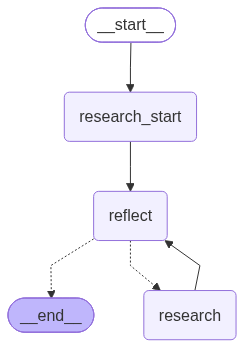

In [11]:
builder = StateGraph(ReflectionAgentState)
builder.add_node("research_start", _research_state)
builder.add_node("research", _research)
builder.add_node("reflect", _reflection_step)

builder.add_edge(START, "research_start")
builder.add_edge("research_start", "reflect")
builder.add_edge("research", "reflect")
builder.add_conditional_edges("reflect", _should_end)
graph = builder.compile()


from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
#i = 3
question = ds_dict["question"][0]
options = "\n".join([f"{i}. {a}" for i, a in enumerate(ds_dict["choices"][0])])

async for _, event in graph.astream({"question": question, "options": options}, stream_mode=["updates"]):
  print(event)

{'research_start': {'answer': "The search results indicate that transportation infrastructure is a significant driver of economic activity and development. While the second search result broadly discusses barriers to economic development in less developed countries, the first result specifically highlights the positive impact of transport infrastructure on economic activity.\n\nConsidering the options and the search results:\n*   **0. a currency:** While essential for complex economies, barter systems have existed, and the lack of currency isn't always the *primary* stopper for economies stuck at the subsistence level.\n*   **1. a well-connected transportation infrastructure:** This is crucial for enabling trade beyond local markets, allowing specialization, and facilitating the movement of goods and resources. Without it, an economy remains isolated and limited to immediate needs, which is the definition of subsistence. The search results confirm its importance for economic activity a

testing by providing a flawed answer

In [14]:
async for _, event in graph.astream({
    "question": question, 
    "options": options,
    "answer": "The main factor is 0. a currency because people need money first."
}, stream_mode=["updates"]):
    print(event)

{'research_start': {'answer': 'The search results confirm the critical role of transportation infrastructure in economic development, particularly in connecting areas and facilitating the movement of goods and people, which is essential for economic growth. It is highlighted as a "key barrier" and an "underlying driver" for development, especially in rural contexts characteristic of many subsistence economies. The results emphasize that inadequate transport hampers access to economic opportunities and markets.\n\n**Argumentation:**\n1.  **Subsistence Economy Defined:** A subsistence economy focuses on producing only what is needed for survival, with minimal surplus and limited trade, often due to isolation and lack of connectivity.\n2.  **Path to Advancement:** Economic advancement requires moving beyond mere survival. This involves generating surpluses, specializing labor, engaging in trade, accessing wider markets, and utilizing resources more efficiently.\n3.  **Role of Transportati